# E3 ablation evaluation

This notebook compares E0, E2 filter-only, E0 abstain-only, and full E2 using only cached predictions and cached Qwen passage scores from E2's results folder.

`rgb_e2_e2_predictions.jsonl` is saved before abstention (filter + generate only). Abstention is applied afterwards by replacing the answer with the refusal sentence when the best original-passage score is strictly less than `tau`, where `tau` is `abstention_threshold` from `rgb_e2_qwen_metrics.json`.


## Overview

| Variant | Passages the LLM sees | Score-based abstention |
|---|---|---|
| E0 | all passages | no |
| E2 filter only | passages above the filter threshold (top passage if none) | no |
| E0 abstain only | all passages | yes |
| E2 full | filtered passages | yes |

"Abstention" means replacing the answer with the fixed refusal sentence when the best Qwen relevance score among the original passages is strictly below tau. It depends only on passage scores, not on the LLM's answer, so it can be applied to cached answers without regenerating.
The E0 prompt also tells the model to refuse by itself, so "no abstention" means no score-based rule, and the model can still refuse on its own.


## 1. Load cached files

Loads the shared contexts, cached Qwen passage scores, and the E0 and E2 predictions from the E2 results folder. Nothing is generated and nothing in that folder is modified.


In [1]:
from pathlib import Path
import hashlib, json
from collections import Counter, defaultdict

REPO_ROOT = Path.cwd()
if not (REPO_ROOT / "E2_Qwen_F1").exists():
    REPO_ROOT = REPO_ROOT.parent
E2_RESULTS = REPO_ROOT / "E2_Qwen_F1" / "results_e2_qwen_f1"
E3_RESULTS = REPO_ROOT / "E3_Ablation" / "results_e3_ablation"
E3_RESULTS.mkdir(exist_ok=True)
def read_jsonl(path):
    if not path.exists():
        raise FileNotFoundError(path)
    return [json.loads(line) for line in path.read_text(encoding="utf-8").splitlines() if line.strip()]

def read_json(path):
    if not path.exists():
        raise FileNotFoundError(path)
    return json.loads(path.read_text(encoding="utf-8"))
paths = {name: E2_RESULTS / name for name in (
    "shared_contexts.jsonl", "shared_contexts_manifest.json",
    "rgb_e2_passage_scores.jsonl", "rgb_e2_e0_predictions.jsonl",
    "rgb_e2_e2_predictions.jsonl", "rgb_e2_e0_predictions.jsonl.meta.json",
    "rgb_e2_e2_predictions.jsonl.meta.json")}
contexts = read_jsonl(paths["shared_contexts.jsonl"])
manifest = read_json(paths["shared_contexts_manifest.json"])
scores = read_jsonl(paths["rgb_e2_passage_scores.jsonl"])
e0 = read_jsonl(paths["rgb_e2_e0_predictions.jsonl"])
e2 = read_jsonl(paths["rgb_e2_e2_predictions.jsonl"])
e0_meta = read_json(paths["rgb_e2_e0_predictions.jsonl.meta.json"])
e2_meta = read_json(paths["rgb_e2_e2_predictions.jsonl.meta.json"])
print({"contexts": len(contexts), "scores": len(scores), "e0": len(e0), "e2_cache": len(e2)})

{'contexts': 1300, 'scores': 6489, 'e0': 1300, 'e2_cache': 1300}


## 2. Validate inputs

Checks the context hash, seed, 30% calibration split and test sizes against E2's manifest, and that both prediction files are complete. A few questions have 3 or 4 passages instead of 5, so the checks use each context's actual passage count.


In [2]:
def row_key(row):
    return (row["condition"], str(row["id"]))

def context_hash(rows):
    text = "".join(json.dumps(row, ensure_ascii=False, sort_keys=True, separators=(",", ":")) + "\n" for row in rows)
    return hashlib.sha256(text.encode("utf-8")).hexdigest()

expected = {"noise_0.0": 300, "noise_0.4": 300, "noise_0.8": 300, "incomplete": 300, "contradictory": 100}
test_expected = {"noise_0.0": 210, "noise_0.4": 210, "noise_0.8": 210, "incomplete": 210, "contradictory": 70}
assert Counter(row["condition"] for row in contexts) == Counter(expected)
assert context_hash(contexts) == manifest["sha256_canonical_jsonl"]
assert manifest["seed"] == 42 and manifest["calibration_fraction"] == 0.3
doc_count_distribution = Counter(len(row["docs"]) for row in contexts)
print("Passage-count distribution:", dict(doc_count_distribution))
assert all(sum(row["condition"] == c and row["split"] == "test" for row in contexts) == n for c, n in test_expected.items())
context_keys = {row_key(row) for row in contexts}
assert len(context_keys) == len(contexts)

def check_predictions(rows, name, complete):
    keys = [row_key(row) for row in rows]
    assert not [k for k, n in Counter(keys).items() if n > 1], f"Duplicate {name} rows"
    missing = context_keys - set(keys)
    assert not (set(keys) - context_keys), f"Unexpected {name} rows"
    if complete:
        assert not missing, f"Incomplete {name}: {len(missing)} missing"
    print(f"{name}: {len(rows)} rows; missing={len(missing)}")
    return missing

check_predictions(e0, "E0", complete=True)
check_predictions(e2, "cached E2", complete=True)
assert e0_meta["context_sha256"] == e2_meta["context_sha256"] == manifest["sha256_canonical_jsonl"]
assert e0_meta["seed"] == e2_meta["seed"] == manifest["seed"]
print("Shared context, split, and metadata checks: OK")


Passage-count distribution: {5: 1293, 4: 3, 3: 4}
E0: 1300 rows; missing=0
cached E2: 1300 rows; missing=0
Shared context, split, and metadata checks: OK


## 3. Score alignment and thresholds

Confirms there is one Qwen score per passage, and reads the filter threshold from the E2 prediction metadata and tau (`abstention_threshold`) from `rgb_e2_qwen_metrics.json`. Tau is read, never re-tuned.


In [3]:
contexts_by_key = {row_key(row): row for row in contexts}
score_groups = defaultdict(list)
for row in scores:
    context = contexts_by_key[row_key(row)]
    assert 0 <= row["doc_idx"] < len(context["docs"])
    score_groups[row_key(row)].append(row)
context_doc_counts = {key: len(context["docs"]) for key, context in contexts_by_key.items()}
incomplete_score_groups = [(k, len(v), context_doc_counts[k]) for k, v in score_groups.items() if len(v) != context_doc_counts[k]]
missing_score_groups = [(k, 0) for k in context_keys if k not in score_groups]
score_gaps = incomplete_score_groups + missing_score_groups
if score_gaps:
    print("ERROR: passage-score cache is incomplete:", len(score_gaps), "context groups")
    print("First gaps:", score_gaps[:5])
    raise RuntimeError("Passage-score cache is incomplete")
print("Passage-score alignment: OK; scores match every context's passage count")

filter_threshold = e2_meta["filter_threshold"]
tau = read_json(E2_RESULTS / "rgb_e2_qwen_metrics.json")["abstention_threshold"]
print("Filter threshold:", filter_threshold, " Abstention threshold:", tau)


Passage-score alignment: OK; scores match every context's passage count
Filter threshold: 1.3702995011356746e-07  Abstention threshold: 4.796591794483425e-07


## 4. Scoring helpers

The constants and scoring helpers below are copied verbatim from **E2_Qwen_F1/E2_qwen_f1_filter.ipynb, cell 4**:

- `contains` (answer matching)
- `REFUSAL`, `REFUSAL_KEY`, `REFUSAL_PHRASES`, and `HEDGE_MARKERS`
- `reject` (refusal/hedge detection)
- `summarize`
- `bal`

This evaluation uses cached predictions only. It does not call an LLM or use a GPU.


In [4]:
REFUSAL="I can not answer the question because of insufficient information in documents.";REFUSAL_KEY="insufficient information"
REFUSAL_PHRASES=[REFUSAL_KEY,"can not answer","cannot answer","unable to answer","cannot be answered","cannot be determined","cannot determine","does not provide","do not provide","doesn't provide","does not contain","do not contain","doesn't contain","does not specify","do not specify","doesn't specify","does not mention","do not mention","not mentioned","no information","no mention","none of the provided documents","none of the documents","not explicitly","not directly"]
HEDGE_MARKERS=["likely","probably","presumably","possibly","might","suggest","infer","implied","indicating","as indicated","assume","speculat","expected to","would be","would have","though"]
def contains(pred,ans):
 pred=pred.lower();ans=[ans] if isinstance(ans,str) else ans
 for part in ans:
  alts=part if isinstance(part,list) else [part]
  if not any(str(a).lower() in pred for a in alts):return False
 return True
def reject(pred):
 p=pred.lower()
 if REFUSAL_KEY in p:return True
 if not any(x in p for x in REFUSAL_PHRASES):return False
 return not (any(x in p for x in HEDGE_MARKERS))
def summarize(name,es,pm):
 co=re=wr=0
 for e in es:
  p=pm[(name,str(e["id"]))];ok=contains(p,e["answer"]);r=reject(p) and not ok;co+=ok;re+=r;wr+=not ok and not r
 if name=="incomplete":return {"n":len(es),"rejection_rate":re/max(1,len(es))}
 return {"n":len(es),"accuracy":co/max(1,len(es)),"rejection_rate":re/max(1,len(es)),"wrong_answer":wr/max(1,len(es))}
def bal(s):return (sum(s[n]["accuracy"] for n in ("noise_0.0","noise_0.4","noise_0.8"))/3+s["incomplete"]["rejection_rate"])/2


## 5. Build the four variants

E0 and the filter-only predictions are read directly from the cache; the two abstention variants are built by substituting the refusal sentence where the best original-passage score is below tau; all four are scored on the test split only with the copied helpers.
The printed check shows how many cached filter-only answers below tau were already refusals.


In [5]:
import csv

metrics = read_json(E2_RESULTS / "rgb_e2_qwen_metrics.json")
tau = metrics["abstention_threshold"]

# Reattach the answer fields used by the reference notebook from its RGB inputs.
def read_json_records(path):
    return [json.loads(line) for line in Path(path).read_text(encoding="utf-8").splitlines() if line.strip()]

refine = read_json_records(REPO_ROOT / "RGB" / "data" / "en_refine.json")
fact = read_json_records(REPO_ROOT / "RGB" / "data" / "en_fact.json")
answers = {}
for condition in ("noise_0.0", "noise_0.4", "noise_0.8", "incomplete"):
    answers.update({(condition, str(row["id"])): row["answer"] for row in refine})
answers.update({("contradictory", str(row["id"])): row["answer"] for row in fact})
eval_rows = []
for row in contexts:
    item = dict(row)
    item["answer"] = answers[row_key(row)]
    eval_rows.append(item)

score_by_key = defaultdict(list)
for row in scores:
    score_by_key[row_key(row)].append(row)
max_original_score = {
    key: max(item["score"] for item in rows)
    for key, rows in score_by_key.items()
}

# This cache is filter + generate only; abstention is applied below.
filter_only = {(row["condition"], str(row["id"])): row["pred"] for row in e2}
e0_predictions = {(row["condition"], str(row["id"])): row["pred"] for row in e0}
e2_filter_only = dict(filter_only)
e2_full = dict(filter_only)
low_score_test = [
    row for row in eval_rows
    if row["split"] == "test" and max_original_score[row_key(row)] < tau
]
refusal_count = sum(e2_filter_only[row_key(row)] == REFUSAL for row in low_score_test)
print(f"Cached E2 exact refusals below tau: {refusal_count}/{len(low_score_test)}")
if low_score_test and refusal_count / len(low_score_test) >= 0.95:
    raise RuntimeError("Nearly all low-score cached E2 answers are already the REFUSAL sentence; stopping because the cache may already include abstention.")
for row in eval_rows:
    key = row_key(row)
    if max_original_score[key] < tau:
        e2_full[key] = REFUSAL

e0_abstain_only = dict(e0_predictions)
e0_abstain_replaced_by_condition = {
    condition: sum(
        max_original_score[row_key(row)] < tau
        for row in eval_rows
        if row["split"] == "test" and row["condition"] == condition
    )
    for condition in ("noise_0.0", "noise_0.4", "noise_0.8", "incomplete", "contradictory")
}
for row in eval_rows:
    key = row_key(row)
    if max_original_score[key] < tau:
        e0_abstain_only[key] = REFUSAL
print(
    "E0 answers replaced by REFUSAL on test split:",
    sum(e0_abstain_replaced_by_condition.values()),
    e0_abstain_replaced_by_condition,
)

conditions = ("noise_0.0", "noise_0.4", "noise_0.8", "incomplete", "contradictory")
test_rows = {condition: [row for row in eval_rows if row["condition"] == condition and row["split"] == "test"] for condition in conditions}
assert {condition: len(rows) for condition, rows in test_rows.items()} == {
    "noise_0.0": 210, "noise_0.4": 210, "noise_0.8": 210, "incomplete": 210, "contradictory": 70
}


summaries = {}
for method, predictions in (("E0", e0_predictions), ("E2_filter_only", e2_filter_only), ("E0_abstain_only", e0_abstain_only), ("E2_full", e2_full)):
    per_condition = {condition: summarize(condition, test_rows[condition], predictions) for condition in conditions}
    summaries[method] = {**per_condition, "balanced": bal(per_condition)}
    print(method, summaries[method])


Cached E2 exact refusals below tau: 113/130
E0 answers replaced by REFUSAL on test split: 130 {'noise_0.0': 1, 'noise_0.4': 2, 'noise_0.8': 18, 'incomplete': 102, 'contradictory': 7}
E0 {'noise_0.0': {'n': 210, 'accuracy': 0.9380952380952381, 'rejection_rate': 0.0380952380952381, 'wrong_answer': 0.023809523809523808}, 'noise_0.4': {'n': 210, 'accuracy': 0.9428571428571428, 'rejection_rate': 0.0380952380952381, 'wrong_answer': 0.01904761904761905}, 'noise_0.8': {'n': 210, 'accuracy': 0.6952380952380952, 'rejection_rate': 0.24285714285714285, 'wrong_answer': 0.06190476190476191}, 'incomplete': {'n': 210, 'rejection_rate': 0.8857142857142857}, 'contradictory': {'n': 70, 'accuracy': 0.5571428571428572, 'rejection_rate': 0.2857142857142857, 'wrong_answer': 0.15714285714285714}, 'balanced': 0.8722222222222222}
E2_filter_only {'noise_0.0': {'n': 210, 'accuracy': 0.9285714285714286, 'rejection_rate': 0.04285714285714286, 'wrong_answer': 0.02857142857142857}, 'noise_0.4': {'n': 210, 'accuracy':

## 6. Reproduction check

Compares E0 and E2 full against the numbers in `rgb_e2_qwen_metrics.json`; any difference above 1e-9 is flagged. This confirms the evaluation here matches E2's.


In [6]:
comparison = []
for method, reference_method in (("E0", "E0"), ("E2_full", "E2")):
    reproduced_metrics = summaries[method]
    reference_metrics = metrics["methods"][reference_method]["test"]
    for condition in conditions:
        for metric_name in sorted(set(reproduced_metrics[condition]) | set(reference_metrics[condition])):
            reproduced_value = reproduced_metrics[condition].get(metric_name)
            reference_value = reference_metrics[condition].get(metric_name)
            difference = None if reproduced_value is None or reference_value is None else reproduced_value - reference_value
            comparison.append({
                "method": method, "condition": condition, "metric": metric_name,
                "reproduced_value": reproduced_value, "reference_value": reference_value, "difference": difference,
            })
    comparison.append({
        "method": method, "condition": "all", "metric": "balanced",
        "reproduced_value": reproduced_metrics["balanced"], "reference_value": reference_metrics["balanced"],
        "difference": reproduced_metrics["balanced"] - reference_metrics["balanced"],
    })

comparison_path = E3_RESULTS / "reproduction_check.csv"
with comparison_path.open("w", newline="", encoding="utf-8") as handle:
    writer = csv.DictWriter(handle, fieldnames=["method", "condition", "metric", "reproduced_value", "reference_value", "difference"])
    writer.writeheader()
    writer.writerows(comparison)
print(f"Wrote {comparison_path}")
print("method,condition,metric,reproduced_value,reference_value,difference")
for row in comparison:
    print(",".join(str(row[field]) for field in ("method", "condition", "metric", "reproduced_value", "reference_value", "difference")))

mismatches = [row for row in comparison if row["difference"] is not None and abs(row["difference"]) > 1e-9]
if mismatches:
    print(f"MISMATCHES: {len(mismatches)}")
else:
    print("All E0 and E2_full comparison metrics match the reported test results.")


Wrote /Users/kiki/Desktop/sc4001-reliable-rag/SC4001-Reliable-RAG/E3_Ablation/results_e3_ablation/reproduction_check.csv
method,condition,metric,reproduced_value,reference_value,difference
E0,noise_0.0,accuracy,0.9380952380952381,0.9380952380952381,0.0
E0,noise_0.0,n,210,210,0
E0,noise_0.0,rejection_rate,0.0380952380952381,0.0380952380952381,0.0
E0,noise_0.0,wrong_answer,0.023809523809523808,0.023809523809523808,0.0
E0,noise_0.4,accuracy,0.9428571428571428,0.9428571428571428,0.0
E0,noise_0.4,n,210,210,0
E0,noise_0.4,rejection_rate,0.0380952380952381,0.0380952380952381,0.0
E0,noise_0.4,wrong_answer,0.01904761904761905,0.01904761904761905,0.0
E0,noise_0.8,accuracy,0.6952380952380952,0.6952380952380952,0.0
E0,noise_0.8,n,210,210,0
E0,noise_0.8,rejection_rate,0.24285714285714285,0.24285714285714285,0.0
E0,noise_0.8,wrong_answer,0.06190476190476191,0.06190476190476191,0.0
E0,incomplete,n,210,210,0
E0,incomplete,rejection_rate,0.8857142857142857,0.8857142857142857,0.0
E0,contradictory,accura

## 7. Final comparison and 2x2 effects

There is one row per variant; "mean noise accuracy" is the average over noise 0.0/0.4/0.8; balanced = half of (mean noise accuracy + incomplete rejection rate).
The 2x2 shows balanced score by filter (no/yes) and abstention (no/yes), and the four effects are differences in balanced score.


In [7]:
import pandas as pd

method_order = ("E0", "E2_filter_only", "E0_abstain_only", "E2_full")
comparison_table = pd.DataFrame([
    {
        "method": method,
        "noise_0.0 accuracy": summaries[method]["noise_0.0"]["accuracy"],
        "noise_0.4 accuracy": summaries[method]["noise_0.4"]["accuracy"],
        "noise_0.8 accuracy": summaries[method]["noise_0.8"]["accuracy"],
        "mean noise accuracy": sum(summaries[method][condition]["accuracy"] for condition in ("noise_0.0", "noise_0.4", "noise_0.8")) / 3,
        "noise_0.8 rejection rate": summaries[method]["noise_0.8"]["rejection_rate"],
        "incomplete rejection rate": summaries[method]["incomplete"]["rejection_rate"],
        "contradictory accuracy": summaries[method]["contradictory"]["accuracy"],
        "contradictory rejection rate": summaries[method]["contradictory"]["rejection_rate"],
        "balanced": summaries[method]["balanced"],
    }
    for method in method_order
])
comparison_table.to_csv(E3_RESULTS / "e3_comparison.csv", index=False)
display(comparison_table.round(3))

balanced_2x2 = pd.DataFrame(
    [[summaries["E0"]["balanced"], summaries["E0_abstain_only"]["balanced"]],
     [summaries["E2_filter_only"]["balanced"], summaries["E2_full"]["balanced"]]],
    index=["no", "yes"], columns=["no", "yes"],
)
balanced_2x2.index.name = "filter"
balanced_2x2.columns.name = "abstention"
print("Balanced score: filter x abstention")
display(balanced_2x2.round(3))
effects = {
    "filter effect without abstention": balanced_2x2.loc["yes", "no"] - balanced_2x2.loc["no", "no"],
    "filter effect with abstention": balanced_2x2.loc["yes", "yes"] - balanced_2x2.loc["no", "yes"],
    "abstention effect without filter": balanced_2x2.loc["no", "yes"] - balanced_2x2.loc["no", "no"],
    "abstention effect with filter": balanced_2x2.loc["yes", "yes"] - balanced_2x2.loc["yes", "no"],
}
for name, difference in effects.items():
    print(f"{name}: {difference:.6f}")


,method,noise_0.0 accuracy,noise_0.4 accuracy,noise_0.8 accuracy,mean noise accuracy,noise_0.8 rejection rate,incomplete rejection rate,contradictory accuracy,contradictory rejection rate,balanced
0,E0,0.938,0.943,0.695,0.859,0.243,0.886,0.557,0.286,0.872
1,E2_filter_only,0.929,0.933,0.767,0.876,0.190,0.952,0.500,0.357,0.914
2,E0_abstain_only,0.933,0.938,0.657,0.843,0.286,0.919,0.514,0.329,0.881
3,E2_full,0.929,0.929,0.719,0.859,0.238,0.967,0.471,0.386,0.913


Balanced score: filter x abstention


abstention,no,yes
filter,,
no,0.872,0.881
yes,0.914,0.913


filter effect without abstention: 0.042063
filter effect with abstention: 0.031746
abstention effect without filter: 0.008730
abstention effect with filter: -0.001587


## 8. Flip analysis

Each test answer is labelled correct / rejected / wrong (incomplete: refused / answered). A flip is a change of label between two variants.
"Changed rows" counts any text change, including wording-only changes, so use the label transitions for conclusions. Reconciliation asserts check that transition counts match the accuracy and rejection differences in the summaries.


In [8]:
def label(condition, pred, answer):
    if condition == "incomplete":
        return "refused" if reject(pred) else "answered"
    if contains(pred, answer):
        return "correct"
    return "rejected" if reject(pred) else "wrong"

prediction_sets = {
    "E0": e0_predictions,
    "E2_filter_only": e2_filter_only,
    "E0_abstain_only": e0_abstain_only,
    "E2_full": e2_full,
}
pairs = (
    ("E0", "E2_filter_only"),
    ("E0", "E0_abstain_only"),
    ("E2_filter_only", "E2_full"),
    ("E0", "E2_full"),
)
transition_rows = []
changed_counts = {}
for before_name, after_name in pairs:
    pair_name = f"{before_name}_to_{after_name}"
    changed_counts[pair_name] = {}
    for condition in conditions:
        transitions = Counter()
        for row in test_rows[condition]:
            key = row_key(row)
            pred_before = prediction_sets[before_name][key]
            pred_after = prediction_sets[after_name][key]
            label_before = label(condition, pred_before, row["answer"])
            label_after = label(condition, pred_after, row["answer"])
            transitions[(label_before, label_after)] += 1
        changed_counts[pair_name][condition] = sum(
            prediction_sets[before_name][row_key(row)] != prediction_sets[after_name][row_key(row)]
            for row in test_rows[condition]
        )
        for (label_before, label_after), count in sorted(transitions.items()):
            transition_rows.append({
                "pair": pair_name, "condition": condition,
                "label_before": label_before, "label_after": label_after, "count": count,
            })
        target = "refused" if condition == "incomplete" else "correct"
        before_target = sum(
            label(condition, prediction_sets[before_name][row_key(row)], row["answer"]) == target
            for row in test_rows[condition]
        )
        after_target = sum(
            label(condition, prediction_sets[after_name][row_key(row)], row["answer"]) == target
            for row in test_rows[condition]
        )
        into_target = sum(count for (old, new), count in transitions.items() if new == target)
        out_of_target = sum(count for (old, new), count in transitions.items() if old == target)
        assert after_target - before_target == into_target - out_of_target
        metric = "rejection_rate" if condition == "incomplete" else "accuracy"
        expected_difference = round((summaries[after_name][condition][metric] - summaries[before_name][condition][metric]) * len(test_rows[condition]))
        assert after_target - before_target == expected_difference
transition_path = E3_RESULTS / "e3_flip_transitions.csv"
pd.DataFrame(transition_rows, columns=["pair", "condition", "label_before", "label_after", "count"]).to_csv(transition_path, index=False)
print("Changed rows per pair and condition:")
for pair_name, counts in changed_counts.items():
    print(pair_name, counts, "total=", sum(counts.values()))
print("Flip transitions:")
display(pd.DataFrame(transition_rows).sort_values(["pair", "condition", "label_before", "label_after"]).reset_index(drop=True))


Changed rows per pair and condition:
E0_to_E2_filter_only {'noise_0.0': 47, 'noise_0.4': 74, 'noise_0.8': 119, 'incomplete': 35, 'contradictory': 53} total= 328
E0_to_E0_abstain_only {'noise_0.0': 1, 'noise_0.4': 1, 'noise_0.8': 9, 'incomplete': 12, 'contradictory': 3} total= 26
E2_filter_only_to_E2_full {'noise_0.0': 0, 'noise_0.4': 1, 'noise_0.8': 10, 'incomplete': 4, 'contradictory': 2} total= 17
E0_to_E2_full {'noise_0.0': 47, 'noise_0.4': 75, 'noise_0.8': 118, 'incomplete': 36, 'contradictory': 52} total= 328
Flip transitions:


,pair,condition,label_before,label_after,count
0,E0_to_E0_abstain_only,contradictory,correct,correct,36
1,E0_to_E0_abstain_only,contradictory,correct,rejected,3
2,E0_to_E0_abstain_only,contradictory,rejected,rejected,20
3,E0_to_E0_abstain_only,contradictory,wrong,wrong,11
4,E0_to_E0_abstain_only,incomplete,answered,answered,17
...,...,...,...,...,...
107,E2_filter_only_to_E2_full,noise_0.4,wrong,wrong,5
108,E2_filter_only_to_E2_full,noise_0.8,correct,correct,151
109,E2_filter_only_to_E2_full,noise_0.8,correct,rejected,10
110,E2_filter_only_to_E2_full,noise_0.8,rejected,rejected,40


### Export changed rows for the failure analysis

Exports rows whose answer changed (filter only -> full E2, and E0 -> filter only) with the best passage score, number of passages kept and tau, as input for the E4 failure analysis.


In [9]:
n_kept_by_key = {}
for key, rows in score_groups.items():
    kept = sum(item["score"] >= filter_threshold for item in rows)
    n_kept_by_key[key] = max(1, kept)

for before_name, after_name in (("E2_filter_only", "E2_full"), ("E0", "E2_filter_only")):
    flipped_rows = []
    for condition in conditions:
        for row in test_rows[condition]:
            key = row_key(row)
            pred_before = prediction_sets[before_name][key]
            pred_after = prediction_sets[after_name][key]
            if pred_before == pred_after:
                continue
            flipped_rows.append({
                "condition": condition, "id": row["id"], "query": row["query"],
                "gold_answer": row["answer"], "split": row["split"],
                "pred_before": pred_before, "pred_after": pred_after,
                "label_before": label(condition, pred_before, row["answer"]),
                "label_after": label(condition, pred_after, row["answer"]),
                "max_original_score": max_original_score[key],
                "n_docs": len(contexts_by_key[key]["docs"]),
                "n_kept": n_kept_by_key[key], "tau": tau,
            })
    output_path = E3_RESULTS / f"e3_flipped_rows_{before_name}_to_{after_name}.csv"
    pd.DataFrame(flipped_rows, columns=[
        "condition", "id", "query", "gold_answer", "split", "pred_before", "pred_after",
        "label_before", "label_after", "max_original_score", "n_docs", "n_kept", "tau",
    ]).to_csv(output_path, index=False)
    print(f"Wrote {output_path}: {len(flipped_rows)} rows")


Wrote /Users/kiki/Desktop/sc4001-reliable-rag/SC4001-Reliable-RAG/E3_Ablation/results_e3_ablation/e3_flipped_rows_E2_filter_only_to_E2_full.csv: 17 rows
Wrote /Users/kiki/Desktop/sc4001-reliable-rag/SC4001-Reliable-RAG/E3_Ablation/results_e3_ablation/e3_flipped_rows_E0_to_E2_filter_only.csv: 328 rows


## 9. Fair abstention test

The original tau was chosen on the calibration split using E0's answers, so abstention may have been tuned for a different system than the filtered one.
This section re-chooses tau on the calibration split using the filter-only answers, with the same objective, and evaluates it once on the test split. The displayed tau values are rounded to three decimals, so a value shown as 0.0 may be a small positive threshold; the CSV preserves the full value. The "correct answers turned into refusals" count here covers only the three noise conditions (11); section 8 also includes contradictory questions (13).


In [10]:
import math

# This mirrors choose_abstain implementation: calibration-only candidates,
# balanced score objective, and first threshold retained on ties.
def choose_abstain_same_logic(condition_rows, passage_scores, predictions):
    pool = ("noise_0.0", "noise_0.4", "noise_0.8", "incomplete")
    calibration_values = sorted({
        max_original_score[row_key(row)]
        for condition in pool
        for row in condition_rows[condition]
        if row["split"] == "calibration"
    })
    best = (-1, None)
    for threshold in [-math.inf] + calibration_values:
        per_condition = {}
        for condition in pool:
            rows = [row for row in condition_rows[condition] if row["split"] == "calibration"]
            adjusted = dict(predictions)
            for row in rows:
                if max_original_score[row_key(row)] < threshold:
                    adjusted[row_key(row)] = REFUSAL
            per_condition[condition] = summarize(condition, rows, adjusted)
        score = bal(per_condition)
        if score > best[0]:
            best = (score, threshold)
    return best[1], best[0]

all_rows = {condition: [row for row in eval_rows if row["condition"] == condition] for condition in conditions}
calibration_filter_tau, _ = choose_abstain_same_logic(all_rows, score_groups, e0_predictions)
assert abs(calibration_filter_tau - tau) <= 1e-12 * max(1.0, abs(tau))
tau_prime, tau_prime_calibration_balanced = choose_abstain_same_logic(all_rows, score_groups, e2_filter_only)

def predictions_with_tau(base_predictions, threshold, rows_by_condition):
    adjusted = dict(base_predictions)
    for condition_rows in rows_by_condition.values():
        for row in condition_rows:
            if max_original_score[row_key(row)] < threshold:
                adjusted[row_key(row)] = REFUSAL
    return adjusted

def evaluate_test_predictions(predictions, threshold, variant, base_predictions=None):
    per_condition = {condition: summarize(condition, test_rows[condition], predictions) for condition in conditions}
    normal_conditions = ("noise_0.0", "noise_0.4", "noise_0.8")
    mean_noise = sum(per_condition[c]["accuracy"] for c in normal_conditions) / 3
    correct_lost = sum(
        label(condition, base_predictions[row_key(row)], row["answer"]) == "correct"
        and label(condition, predictions[row_key(row)], row["answer"]) == "rejected"
        for condition in normal_conditions for row in test_rows[condition]
    ) if base_predictions is not None else 0
    incomplete_gained = sum(
        label("incomplete", base_predictions[row_key(row)], row["answer"]) == "answered"
        and label("incomplete", predictions[row_key(row)], row["answer"]) == "refused"
        for row in test_rows["incomplete"]
    ) if base_predictions is not None else 0
    return {
        "variant": variant, "tau": threshold,
        "noise_0.0 accuracy": per_condition["noise_0.0"]["accuracy"],
        "noise_0.4 accuracy": per_condition["noise_0.4"]["accuracy"],
        "noise_0.8 accuracy": per_condition["noise_0.8"]["accuracy"],
        "mean noise accuracy": mean_noise,
        "incomplete rejection rate": per_condition["incomplete"]["rejection_rate"],
        "contradictory accuracy": per_condition["contradictory"]["accuracy"],
        "balanced": bal(per_condition),
        "correct answers turned into refusals vs filter-only": correct_lost,
        "incomplete questions gained as refusals vs filter-only": incomplete_gained,
    }

filter_test = evaluate_test_predictions(e2_filter_only, math.inf, "E2_filter_only")
filter_tau_predictions = predictions_with_tau(e2_filter_only, tau, test_rows)
filter_tau_prime_predictions = predictions_with_tau(e2_filter_only, tau_prime, test_rows)
comparison_tau = pd.DataFrame([
    filter_test,
    evaluate_test_predictions(filter_tau_predictions, tau, "E2_filter_only + tau", e2_filter_only),
    evaluate_test_predictions(filter_tau_prime_predictions, tau_prime, "E2_filter_only + tau_prime", e2_filter_only),
])
comparison_tau.to_csv(E3_RESULTS / "e3_tau_prime_comparison.csv", index=False)
print("tau:", tau, "tau_prime:", tau_prime)
print("tau_prime abstains on any test question:", any(
    max_original_score[row_key(row)] < tau_prime
    for condition_rows in test_rows.values() for rows in [condition_rows] for row in rows
))
display(comparison_tau.round(3))


tau: 4.796591794483425e-07 tau_prime: -inf
tau_prime abstains on any test question: False


,variant,tau,noise_0.0 accuracy,noise_0.4 accuracy,noise_0.8 accuracy,mean noise accuracy,incomplete rejection rate,contradictory accuracy,balanced,correct answers turned into refusals vs filter-only,incomplete questions gained as refusals vs filter-only
0,E2_filter_only,inf,0.929,0.933,0.767,0.876,0.952,0.500,0.914,0,0
1,E2_filter_only + tau,0.0,0.929,0.929,0.719,0.859,0.967,0.471,0.913,11,3
2,E2_filter_only + tau_prime,-inf,0.929,0.933,0.767,0.876,0.952,0.500,0.914,0,0


## 10. Tau sweep

This shows whether score-based abstention helps at any threshold. The grid is log-spaced because Qwen scores span many orders of magnitude.
The test-split curve is for analysis only and must not be used to pick a threshold.


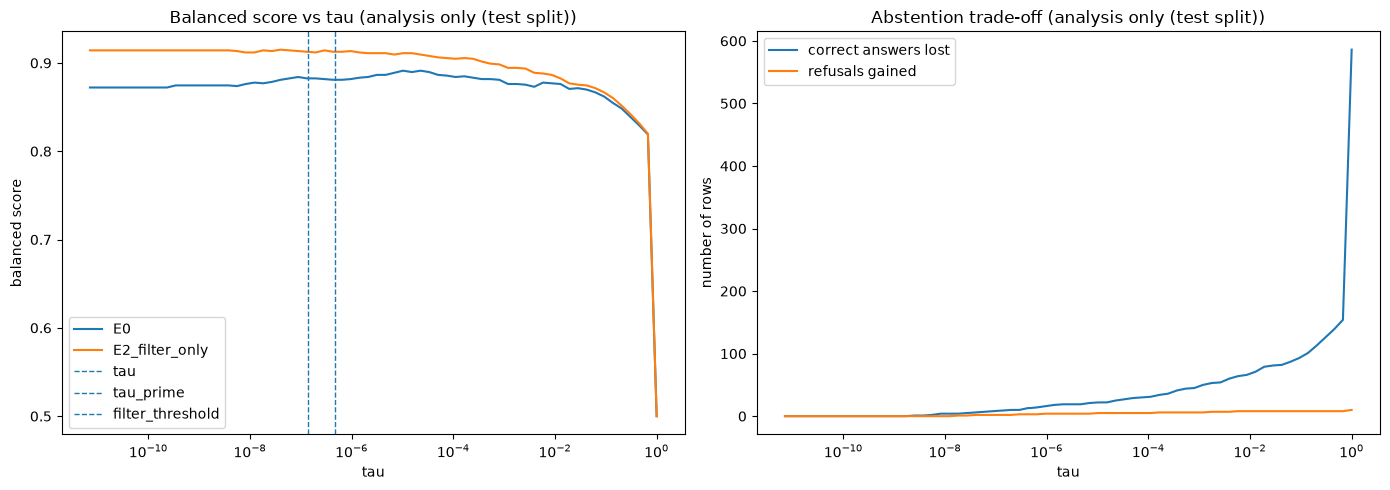

Sweep best-balanced tau (analysis only):
E0 tau= 1.028278971157095e-05 balanced= 0.8912698412698412
E2_filter_only tau= 4.0194304894724773e-08 balanced= 0.9150793650793652


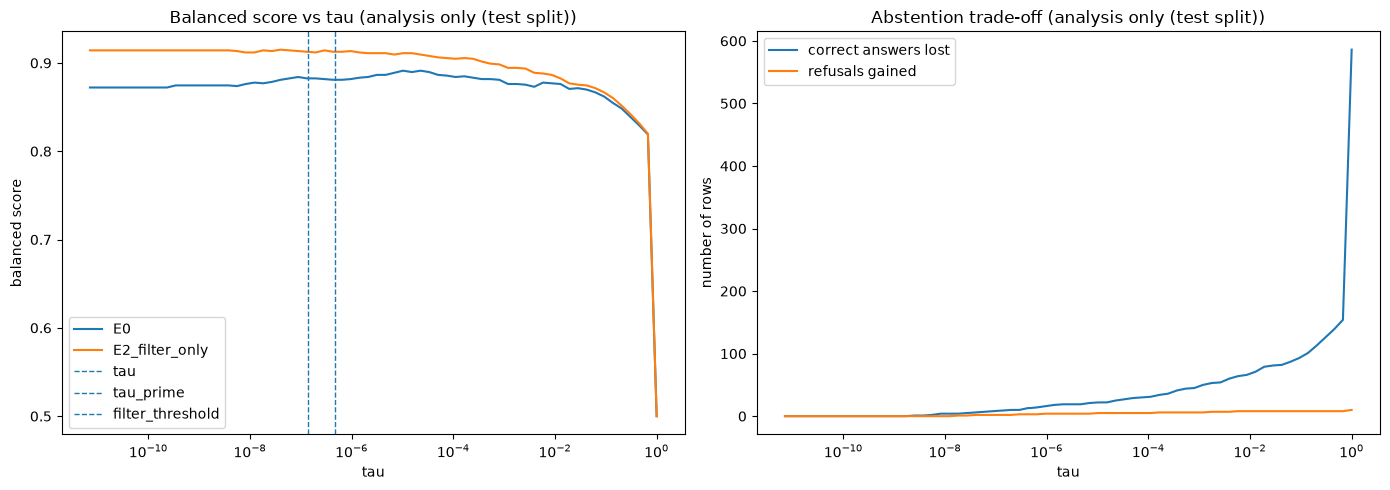

In [11]:
import numpy as np

positive_scores = [score for score in max_original_score.values() if score > 0]
assert positive_scores, "No positive best-passage scores available for a log-spaced sweep"
sweep_min = min(positive_scores)
sweep_max = max(positive_scores)
below_all_scores = sweep_min / 10
sweep_values = set(float(value) for value in np.logspace(math.log10(sweep_min), math.log10(sweep_max), 60))
sweep_values.update({float(below_all_scores), float(tau), float(tau_prime), float(filter_threshold)})
sweep_values = sorted(sweep_values)

def sweep_metrics(base_name, base_predictions, threshold, split):
    rows_by_condition = {
        condition: [row for row in all_rows[condition] if row["split"] == split]
        for condition in conditions
    }
    adjusted = predictions_with_tau(base_predictions, threshold, rows_by_condition)
    per_condition = {
        condition: summarize(condition, rows_by_condition[condition], adjusted)
        for condition in conditions
    }
    base_labels = {
        row_key(row): label(condition, base_predictions[row_key(row)], row["answer"])
        for condition in conditions for row in rows_by_condition[condition]
    }
    adjusted_labels = {
        row_key(row): label(condition, adjusted[row_key(row)], row["answer"])
        for condition in conditions for row in rows_by_condition[condition]
    }
    correct_lost = sum(
        base_labels[row_key(row)] == "correct" and adjusted_labels[row_key(row)] == "rejected"
        for condition in ("noise_0.0", "noise_0.4", "noise_0.8", "contradictory")
        for row in rows_by_condition[condition]
    )
    incomplete_gained = sum(
        base_labels[row_key(row)] == "answered" and adjusted_labels[row_key(row)] == "refused"
        for row in rows_by_condition["incomplete"]
    )
    mean_noise = sum(per_condition[c]["accuracy"] for c in ("noise_0.0", "noise_0.4", "noise_0.8")) / 3
    return {
        "base": base_name, "split": split, "tau": threshold,
        "balanced": bal(per_condition), "mean noise accuracy": mean_noise,
        "incomplete rejection rate": per_condition["incomplete"]["rejection_rate"],
        "contradictory accuracy": per_condition["contradictory"]["accuracy"],
        "number of rows replaced": sum(
            max_original_score[row_key(row)] < threshold
            for condition in conditions for row in rows_by_condition[condition]
        ),
        "correct answers turned into refusals": correct_lost,
        "incomplete questions gained as refusals": incomplete_gained,
    }

sweep_rows = [
    sweep_metrics(base_name, base_predictions, threshold, split)
    for threshold in sweep_values
    for base_name, base_predictions in (("E0", e0_predictions), ("E2_filter_only", e2_filter_only))
    for split in ("calibration", "test")
]
sweep = pd.DataFrame(sweep_rows)
existing_summaries = {
    ("E0", tau): summaries["E0_abstain_only"]["balanced"],
    ("E2_filter_only", tau): summaries["E2_full"]["balanced"],
}
for (base_name, threshold), expected in existing_summaries.items():
    actual = float(sweep[(sweep.base == base_name) & (sweep.split == "test") & (sweep.tau == threshold)]["balanced"].iloc[0])
    assert abs(actual - expected) <= 1e-9
for base_name, base_predictions in (("E0", e0_predictions), ("E2_filter_only", e2_filter_only)):
    unchanged = sweep[(sweep.base == base_name) & (sweep.split == "test") & (sweep.tau == below_all_scores)].iloc[0]
    base_summary = {condition: summarize(condition, test_rows[condition], base_predictions) for condition in conditions}
    assert abs(unchanged["balanced"] - bal(base_summary)) <= 1e-9
    assert unchanged["number of rows replaced"] == 0
sweep.to_csv(E3_RESULTS / "e3_tau_sweep.csv", index=False)

import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for base_name in ("E0", "E2_filter_only"):
    curve = sweep[(sweep.base == base_name) & (sweep.split == "test")].sort_values("tau")
    curve = curve[curve.tau > 0]
    axes[0].plot(curve.tau, curve.balanced, label=base_name)
for marker, name in ((tau, "tau"), (tau_prime, "tau_prime"), (filter_threshold, "filter_threshold")):
    axes[0].axvline(marker, linestyle="--", linewidth=1, label=name)
axes[0].set_xscale("log")
axes[0].set_xlabel("tau")
axes[0].set_ylabel("balanced score")
axes[0].set_title("Balanced score vs tau (analysis only (test split))")
axes[0].legend()
filter_curve = sweep[(sweep.base == "E2_filter_only") & (sweep.split == "test")].sort_values("tau")
filter_curve = filter_curve[filter_curve.tau > 0]
axes[1].plot(filter_curve.tau, filter_curve["correct answers turned into refusals"], label="correct answers lost")
axes[1].plot(filter_curve.tau, filter_curve["incomplete questions gained as refusals"], label="refusals gained")
axes[1].set_xscale("log")
axes[1].set_xlabel("tau")
axes[1].set_ylabel("number of rows")
axes[1].set_title("Abstention trade-off (analysis only (test split))")
axes[1].legend()
fig.tight_layout()
fig.savefig(E3_RESULTS / "e3_tau_sweep.png", dpi=150)
display(fig)
print("Sweep best-balanced tau (analysis only):")
for base_name in ("E0", "E2_filter_only"):
    best = sweep[(sweep.base == base_name) & (sweep.split == "test")].sort_values(["balanced", "tau"], ascending=[False, True]).iloc[0]
    print(base_name, "tau=", best["tau"], "balanced=", best["balanced"])


## 11. Filter diagnostics

This section uses saved filter measurements and cross-checks how many passages the filter keeps in the test split.
The diagnostics help separate passage-selection coverage from downstream answer changes.


In [12]:
diagnostics = json.loads((E2_RESULTS / "rgb_e2_qwen_metrics.json").read_text(encoding="utf-8"))
for section_name in ("filter_calibration", "relevance"):
    print(section_name, "keys:", list(diagnostics.get(section_name, {})))
    print(section_name, "structure:", json.dumps(diagnostics.get(section_name), indent=2))

filter_calibration = diagnostics.get("filter_calibration", {})
filter_counts = filter_calibration.get("counts", {})
filter_rows = []
for key in ("true_passage_kept", "fake_passage_kept", "both_kept"):
    if key in filter_calibration:
        filter_rows.append({"source": "filter_calibration", "metric": key, "condition": "calibration", "value": filter_calibration[key]})
    elif key in diagnostics.get("relevance", {}):
        for condition, values in diagnostics["relevance"].items():
            if key in values:
                filter_rows.append({"source": "relevance", "metric": key, "condition": condition, "value": values[key]})
    else:
        print("Metric not present:", key)
for key in ("tp", "fp", "fn", "F1"):
    source_key = "calibration_positive_doc_f1" if key == "F1" else key
    value = filter_calibration.get(source_key, filter_counts.get(key))
    if value is not None:
        filter_rows.append({"source": "filter_calibration", "metric": key, "condition": "calibration", "value": value})
relevance_rows = []
for condition, values in diagnostics.get("relevance", {}).items():
    for metric, value in values.items():
        relevance_rows.append({"source": "relevance", "metric": metric, "condition": condition, "value": value})
print("filter_calibration is calibration data; relevance is reported test data.")
display(pd.DataFrame(filter_rows))
display(pd.DataFrame(relevance_rows))

cross_check_rows = []
for condition in conditions:
    kept_counts = []
    fallback_count = 0
    for row in test_rows[condition]:
        key = row_key(row)
        scores_for_row = score_groups[key]
        kept = sum(item["score"] >= filter_threshold for item in scores_for_row)
        if kept == 0:
            fallback_count += 1
        kept_counts.append(max(1, kept))
    cross_check_rows.append({
        "source": "test_cross_check", "metric": "mean_passages_kept", "condition": condition,
        "value": sum(kept_counts) / len(kept_counts),
    })
    cross_check_rows.append({
        "source": "test_cross_check", "metric": "fallback_questions", "condition": condition,
        "value": fallback_count,
    })
cross_check = pd.DataFrame(cross_check_rows)
display(cross_check)
pd.DataFrame(filter_rows + relevance_rows + cross_check_rows).to_csv(E3_RESULTS / "e3_filter_diagnostics.csv", index=False)


filter_calibration keys: ['calibration_positive_doc_f1', 'counts']
filter_calibration structure: {
  "calibration_positive_doc_f1": 0.8753726893261777,
  "counts": {
    "tp": 734,
    "fp": 133,
    "fn": 76,
    "n": 1350
  }
}
relevance keys: ['noise_0.0', 'noise_0.4', 'noise_0.8']
relevance structure: {
  "noise_0.0": {
    "positive_recall": 0.8971428571428571,
    "passage_precision": 1.0,
    "kept_fraction": 0.8971428571428571,
    "n_test": 210
  },
  "noise_0.4": {
    "positive_recall": 0.9063492063492062,
    "passage_precision": 0.8835714285714287,
    "kept_fraction": 0.6380952380952379,
    "n_test": 210
  },
  "noise_0.8": {
    "positive_recall": 0.9619047619047619,
    "passage_precision": 0.6630952380952381,
    "kept_fraction": 0.3685714285714286,
    "n_test": 210
  }
}
Metric not present: true_passage_kept
Metric not present: fake_passage_kept
Metric not present: both_kept
filter_calibration is calibration data; relevance is reported test data.


,source,metric,condition,value
0,filter_calibration,tp,calibration,734.000000
1,filter_calibration,fp,calibration,133.000000
2,filter_calibration,fn,calibration,76.000000
3,filter_calibration,F1,calibration,0.875373


,source,metric,condition,value
0,relevance,positive_recall,noise_0.0,0.897143
1,relevance,passage_precision,noise_0.0,1.000000
2,relevance,kept_fraction,noise_0.0,0.897143
3,relevance,n_test,noise_0.0,210.000000
4,relevance,positive_recall,noise_0.4,0.906349
5,relevance,passage_precision,noise_0.4,0.883571
6,relevance,kept_fraction,noise_0.4,0.638095
7,relevance,n_test,noise_0.4,210.000000
8,relevance,positive_recall,noise_0.8,0.961905
9,relevance,passage_precision,noise_0.8,0.663095


,source,metric,condition,value
0,test_cross_check,mean_passages_kept,noise_0.0,4.485714
1,test_cross_check,fallback_questions,noise_0.0,1.000000
2,test_cross_check,mean_passages_kept,noise_0.4,3.190476
3,test_cross_check,fallback_questions,noise_0.4,2.000000
4,test_cross_check,mean_passages_kept,noise_0.8,1.842857
5,test_cross_check,fallback_questions,noise_0.8,12.000000
6,test_cross_check,mean_passages_kept,incomplete,1.480952
7,test_cross_check,fallback_questions,incomplete,90.000000
8,test_cross_check,mean_passages_kept,contradictory,2.542857
9,test_cross_check,fallback_questions,contradictory,5.000000


## 12. Conclusions and caveats

Conclusions (test split):
- Filtering does most of the work. Balanced score rises from 0.872 (E0) to 0.914 (filter only); the filter effect is +0.042 without abstention and +0.032 with it.
- Abstention adds little once the filter is in place: 0.914 -> 0.913. Adding it to the filtered answers turned 13 correct answers into refusals (10 at noise 0.8, 2 contradictory, 1 at noise 0.4) and gained only 3 correct refusals on incomplete questions. Among the 130 test questions with a best score below tau, 113 of the filter-only answers were already exact refusals, so the rule had little left to change.
- Full E2's mean noise accuracy (0.859) is the same as E0's, so its balanced gain over E0 comes from rejecting more incomplete questions (0.886 -> 0.967). Filtering alone improves both halves (mean noise accuracy 0.876, incomplete rejection 0.952).
- Contradictory accuracy is lower with filtering (0.557 to 0.500; full E2 0.471). That is a drop of 4 questions out of 70, so it is only a hint that filtering does not help the model pick the true passage; the failure analysis checks this.
- Abstention is not a tuning problem: re-choosing tau on the filtered answers selects no abstention, and even the best test-split threshold changes filter-only by less than 0.001.
- Abstention helps the unfiltered system modestly (best 0.891 vs 0.872) but does not reach filter-only (0.914).
- The filter is imperfect: it drops about 10% of relevant passages at noise 0.0, and it keeps many irrelevant ones at noise 0.8 (precision 0.66). On incomplete questions it often falls back to a single passage.

Caveats:
- The test set is small (210 questions per noise condition, 70 contradictory). One question is about 0.5 points in the noise conditions and 1.4 points for contradictory, so differences of about a point or less, including the 0.002 balanced difference between filter-only and full E2, are within noise.
- Tau was originally chosen on the calibration split using E0's answers; section 9 repeats the choice using the filtered answers. The tau sweep runs on the test split and is analysis only, an optimistic upper bound for abstention.
- E0 here is the local Ollama run behind E2's results, so its numbers differ from the cluster-run E0 in the baseline results. Do not mix the two in one table.
- Single run with one answer model (Qwen2.5-3B-Instruct) and no confidence intervals.
- The saved filter measurements do not cover contradictory questions, so whether the filter keeps the true or the fake passage is left to the failure analysis.

